# 5 Two-Dimensional Discrete Wavelet Transform



## 5.7 Visualization Examples

### 5.7.1 Decomposition Diagrams

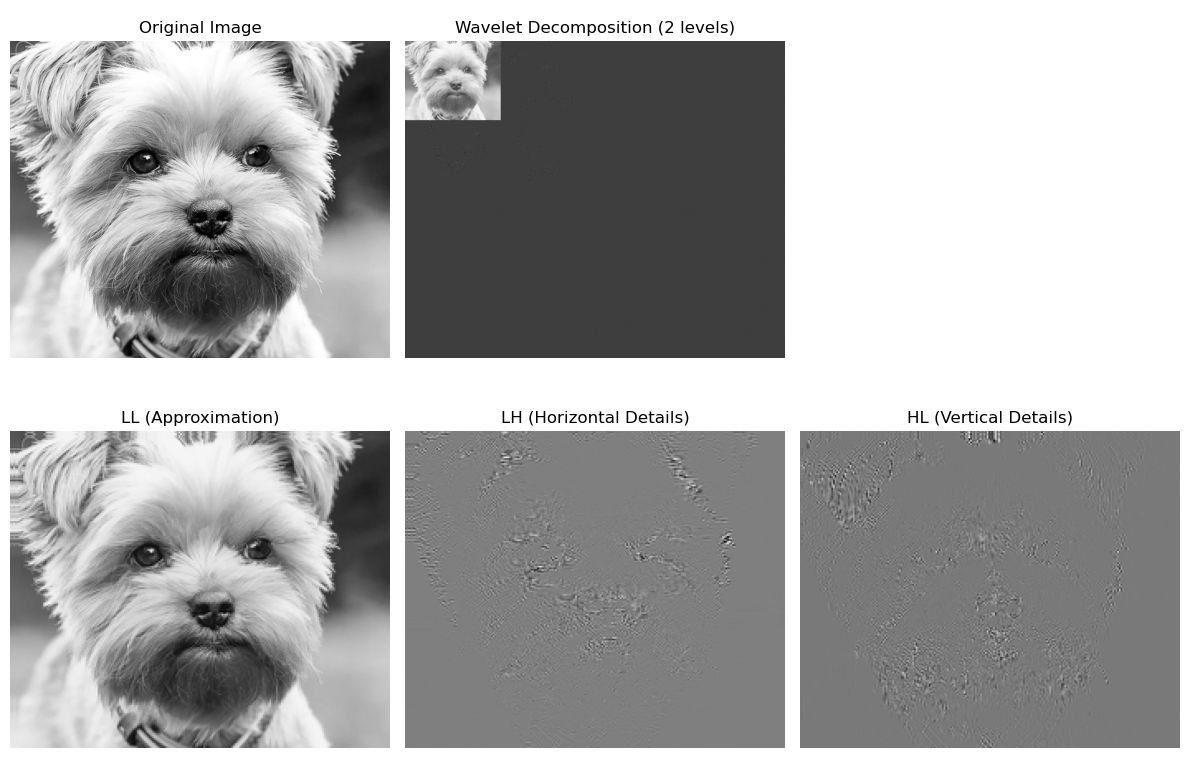

✅ Combined figure saved to: d:\project-workspace\jupyter-books\wavelet-book\script\output\figure_9_1_dwt.png


In [ ]:
# this code

import matplotlib.pyplot as plt
import pywt
import imageio.v2 as imageio
import numpy as np
import os

def visualize_2d_dwt_combined(image, wavelet='db4', levels=2, save_path='./output/figure_9_1_dwt.png'):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    
    # Convert to grayscale if RGB
    if image.ndim == 3:
        image = np.mean(image, axis=2)
    
    # Perform 2D DWT
    coeffs = pywt.wavedec2(image, wavelet, level=levels)
    coeffs_array, _ = pywt.coeffs_to_array(coeffs)
    
    # Create combined figure
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    
    # Original image
    axes[0, 0].imshow(image, cmap='gray')
    axes[0, 0].set_title('Original Image')
    axes[0, 0].axis('off')
    
    # Full decomposition array
    axes[0, 1].imshow(coeffs_array, cmap='gray')
    axes[0, 1].set_title(f'Wavelet Decomposition ({levels} levels)')
    axes[0, 1].axis('off')
    
    # Empty slot for symmetry
    axes[0, 2].axis('off')
    
    # LL (Approximation)
    LL = coeffs[0]
    axes[1, 0].imshow(LL, cmap='gray')
    axes[1, 0].set_title('LL (Approximation)')
    axes[1, 0].axis('off')
    
    # LH, HL from first level
    LH, HL, HH = coeffs[1]
    axes[1, 1].imshow(LH, cmap='gray')
    axes[1, 1].set_title('LH (Horizontal Details)')
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(HL, cmap='gray')
    axes[1, 2].set_title('HL (Vertical Details)')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    
    print(f"✅ Combined figure saved to: {os.path.abspath(save_path)}")

# Load your image
image_path = './data/little-dog.jpg'
img = imageio.imread(image_path)

# Run combined visualization
visualize_2d_dwt_combined(img, wavelet='db4', levels=2, save_path='./output/2d_dog_dwt.png')


### 5.7.2 Reconstructed Subbands

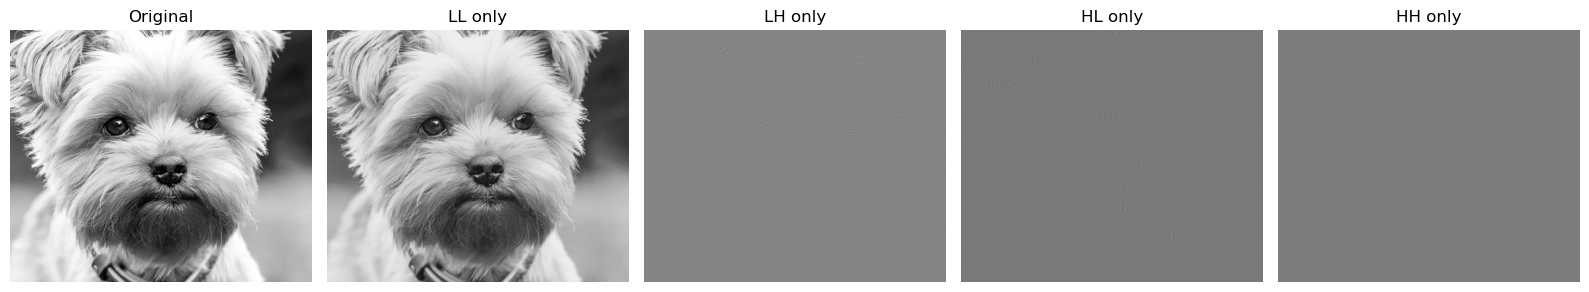


Reconstruction metrics (vs. original):
LL only -> MSE: 0.000686, PSNR: 31.64 dB, SSIM: 0.9481
LH only -> MSE: 0.475979, PSNR: 3.22 dB, SSIM: 0.0003
HL only -> MSE: 0.476073, PSNR: 3.22 dB, SSIM: 0.0002
HH only -> MSE: 0.476283, PSNR: 3.22 dB, SSIM: 0.0000


In [ ]:
import matplotlib.pyplot as plt
import pywt
import numpy as np
import imageio.v2 as imageio
from skimage.metrics import structural_similarity as ssim

def reconstruct_subbands(coeffs, wavelet='db4', original=None):
    """Reconstruct image from individual subbands and show metrics."""
    
    LL, (LH, HL, HH) = coeffs
    
    # LL only
    coeffs_ll = (LL, (np.zeros_like(LH), np.zeros_like(HL), np.zeros_like(HH)))
    recon_ll = pywt.idwt2(coeffs_ll, wavelet)
    
    # LH only
    coeffs_lh = (np.zeros_like(LL), (LH, np.zeros_like(HL), np.zeros_like(HH)))
    recon_lh = pywt.idwt2(coeffs_lh, wavelet)
    
    # HL only
    coeffs_hl = (np.zeros_like(LL), (np.zeros_like(LH), HL, np.zeros_like(HH)))
    recon_hl = pywt.idwt2(coeffs_hl, wavelet)
    
    # HH only
    coeffs_hh = (np.zeros_like(LL), (np.zeros_like(LH), np.zeros_like(HL), HH))
    recon_hh = pywt.idwt2(coeffs_hh, wavelet)
    
    reconstructions = {
        'LL': recon_ll,
        'LH': recon_lh,
        'HL': recon_hl,
        'HH': recon_hh
    }
    
    # Plot
    fig, axes = plt.subplots(1, 5, figsize=(16, 4))
    axes[0].imshow(original, cmap='gray')
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    for i, (name, img) in enumerate(reconstructions.items(), start=1):
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"{name} only")
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.savefig("./output/2d_dwt_reconstructions.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # Metrics
    if original is not None:
        print("\nReconstruction metrics (vs. original):")
        for name, img in reconstructions.items():
            mse = np.mean((original - img) ** 2)
            psnr = 10 * np.log10(1.0 / mse) if mse != 0 else np.inf
            ssim_val = ssim(original, img, data_range=img.max() - img.min())
            print(f"{name} only -> MSE: {mse:.6f}, PSNR: {psnr:.2f} dB, SSIM: {ssim_val:.4f}")
    
    return reconstructions

# Example usage
image_path = './data/little-dog.jpg'
img = imageio.imread(image_path)

# Convert to grayscale [0,1]
if img.ndim == 3:
    img = np.mean(img, axis=2)
img = img / 255.0

# Perform one-level 2D DWT
coeffs = pywt.dwt2(img, 'db4')

# Reconstruct and evaluate
reconstructed = reconstruct_subbands(coeffs, wavelet='db4', original=img)
